In [1]:
pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 16.3 MB/s  0:00:006.6 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 15.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 18.1 MB/s  0:00:00 22.3 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib] 6/7 [matplotlib]ow]
Note: you may need to restart the kernel to use updated packages.


In [5]:
import pandas as pd
import matplotlib.pyplot as plt

In [7]:
import pandas as pd

In [10]:
evictions = pd.read_csv("data/Evictions_20240615.csv")

In [13]:
evictions.info()

<class 'pandas.DataFrame'>
RangeIndex: 92514 entries, 0 to 92513
Data columns (total 20 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Court Index Number         92514 non-null  str    
 1   Docket Number              92514 non-null  int64  
 2   Eviction Address           92514 non-null  str    
 3   Eviction Apartment Number  78045 non-null  str    
 4   Executed Date              92514 non-null  str    
 5   Marshal First Name         92514 non-null  str    
 6   Marshal Last Name          92514 non-null  str    
 7   Residential/Commercial     92514 non-null  str    
 8   BOROUGH                    92514 non-null  str    
 9   Eviction Postcode          92514 non-null  int64  
 10  Ejectment                  92514 non-null  str    
 11  Eviction/Legal Possession  92514 non-null  str    
 12  Latitude                   83973 non-null  float64
 13  Longitude                  83973 non-null  float64
 14  C

In [15]:
evictions['Executed Date'] = evictions['Executed Date'].astype('datetime64[ns]')

In [16]:
evictions.dtypes

Court Index Number                      str
Docket Number                         int64
Eviction Address                        str
Eviction Apartment Number               str
Executed Date                datetime64[ns]
Marshal First Name                      str
Marshal Last Name                       str
Residential/Commercial                  str
BOROUGH                                 str
Eviction Postcode                     int64
Ejectment                               str
Eviction/Legal Possession               str
Latitude                            float64
Longitude                           float64
Community Board                     float64
Council District                    float64
Census Tract                        float64
BIN                                 float64
BBL                                 float64
NTA                                     str
dtype: object

In [17]:
# This creates a new DataFrame called evictions_over_time, using Executed Date as its index.
# An index is what pandas uses to label and organize rows. By default, pandas assigns row numbers such as 0, 1, and 2. 
# Why is this useful? A datetime index allows pandas to perform time-based operations, such as counting evictions by month.

evictions_over_time = evictions.set_index("Executed Date")

In [18]:
evictions_over_time.head()

,Court Index Number,Docket Number,Eviction Address,Eviction Apartment Number,Marshal First Name,Marshal Last Name,Residential/Commercial,BOROUGH,Eviction Postcode,Ejectment,Eviction/Legal Possession,Latitude,Longitude,Community Board,Council District,Census Tract,BIN,BBL,NTA
Executed Date,,,,,,,,,,,,,,,,,,,
2024-01-04,318594/23,14150,172 WEST 107TH ST,1W,David,Smith,Residential,MANHATTAN,10025,Not an Ejectment,Possession,40.800704,-73.964267,7.0,7.0,193.0,1055977.0,1.018610e+09,Morningside Heights
2018-11-29,016134/18,86658,70 BRUCKNER BLVD.,12E,Henry,Daley,Residential,BRONX,10454,Not an Ejectment,Possession,40.806321,-73.926264,1.0,8.0,19.0,2116953.0,2.022950e+09,Mott Haven-Port Morris
2022-11-30,300816/222,209993,23 WYONA STREET,NaN,Richard,Capuano,Residential,QUEENS,11207,Not an Ejectment,Possession,40.678696,-73.894650,5.0,37.0,1146.0,3389505.0,3.036630e+09,Cypress Hills-City Line
2017-04-12,K52673/17,94663,601 BRIGHTON BEACH A VE,FRONT GROUND STORE,Darlene,Barone,Commercial,BROOKLYN,11235,Not an Ejectment,Possession,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-01-18,79638/19,173756,540 NEW LOTS AVE,1R,Alfred,Locascio,Residential,BROOKLYN,11207,Not an Ejectment,Possession,40.663958,-73.888289,5.0,42.0,1122.0,3096753.0,3.043040e+09,East New York (Pennsylvania Ave)


In [19]:
# Resampling in pandas is a powerful method used to control the reporting frequency of time-series data.
# Groups rows into monthly time intervals, using the datetime index.
# Selects the court index number column from those monthly groups.
# Counts the non-null values in that column for each month. It doesn't count empty or missing values.
# Saves the resulting monthly counts in a new variable called evictions_tally.

evictions_tally = evictions_over_time.resample('ME')['Court Index Number'].count()## ME is month, month is depreciated. W is week, D is day ? 
evictions_tally.head()


Executed Date
2017-01-31    2237
2017-02-28    1695
2017-03-31    2040
2017-04-30    1860
2017-05-31    2080
Freq: ME, Name: Court Index Number, dtype: int64

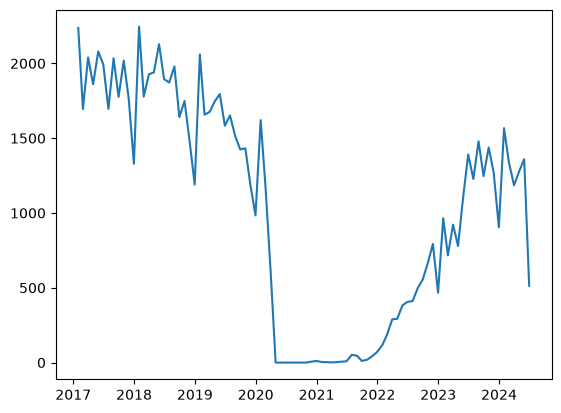

In [20]:
## plotting the evictions data as a chart

plt.plot(evictions_tally)

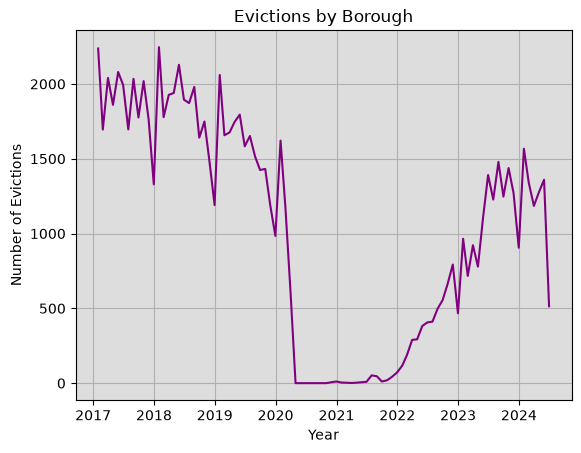

In [23]:
# This line of code reates a single axis and a blank canvas for you to plot data on 
fig, ax = plt.subplots()

ax.plot(evictions_tally, color="purple")
ax.set_title("Evictions by Borough")
ax.set_xlabel("Year")
ax.set_ylabel("Number of Evictions")
ax.set_facecolor('#ddd')
plt.grid(True)

In [27]:


evictions_by_borough = evictions["BOROUGH"].value_counts().reset_index()
evictions_by_borough

,BOROUGH,count
0,BRONX,29264
1,BROOKLYN,26830
2,QUEENS,17803
3,MANHATTAN,15189
4,STATEN ISLAND,3428


<Axes: ylabel='BOROUGH'>

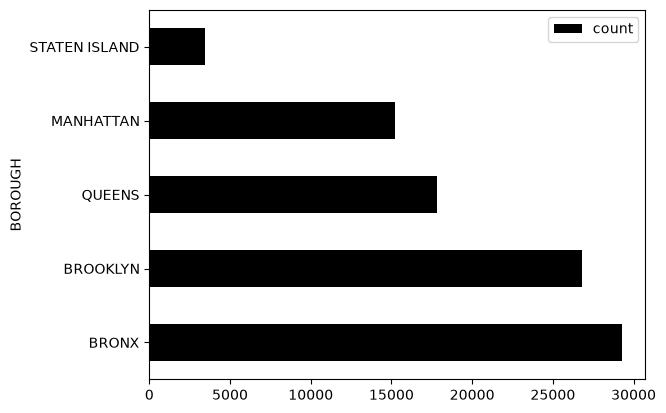

In [30]:
evictions_by_borough.plot(kind="barh",x="BOROUGH", y="count", color="#000000")

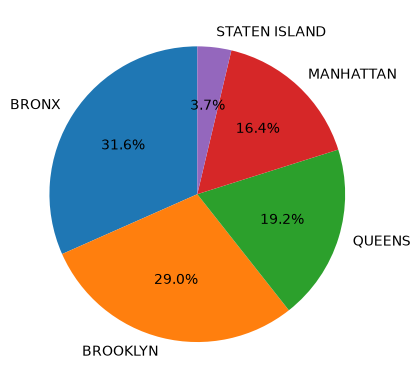

In [35]:
plt.pie(
    evictions_by_borough["count"],
    labels=evictions_by_borough["BOROUGH"],
    autopct="%1.1f%%",
    startangle=90
)

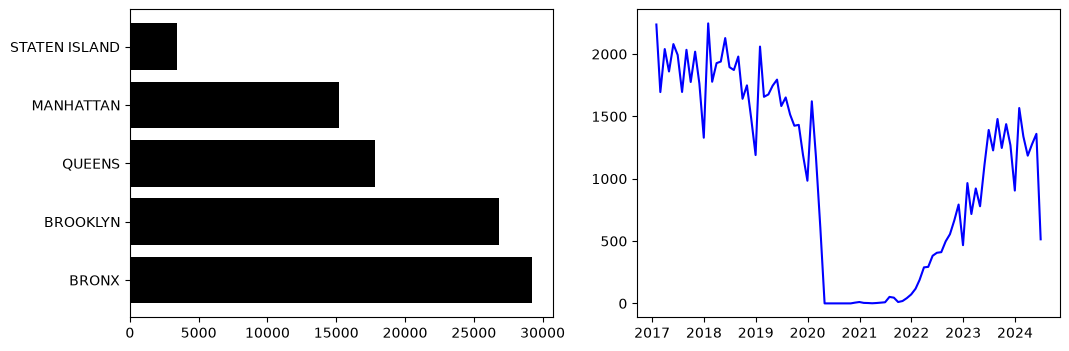

In [38]:
fig, ax = plt.subplots(1,2)

fig.set_size_inches(12,4) 
ax[0].barh(evictions_by_borough["BOROUGH"],evictions_by_borough["count"],color="black")
ax[1].plot(evictions_tally, color="blue")

In [ ]:
plt.plot(evictions_tally)
plt.savefig('../output/chart.svg')
plt.savefig('../output/chart.png')